In [1]:
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
import os
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.stattools import kpss
from tabulate import tabulate
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
from scipy.signal import detrend
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import pmdarima as pm
from statsmodels.tsa.ar_model import AutoReg
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing


warnings.simplefilter('ignore', InterpolationWarning)

In [3]:
os.environ["KAGGLEHUB_CACHE"] = "data/kagglehub_cache"

path = kagglehub.dataset_download(
    "akhiljethwa/world-energy-statistics"
)

print("Dataset path:", path)

df = pd.read_csv(path + "/World Energy Overview.csv")

print(df.head())
print(df.info())
print(df.describe())
duplicates_count = df.duplicated().sum()
print(f"\nКоличество дубликатов: {duplicates_count}")

Dataset path: data/kagglehub_cache\datasets\akhiljethwa\world-energy-statistics\versions\2
         Date  Total Fossil Fuels Production  \
0  1973-01-31                       4.932632   
1  1973-02-28                       4.729582   
2  1973-03-31                       4.946902   
3  1973-04-30                       4.716271   
4  1973-05-31                       4.956995   

   Nuclear Electric Power Production  Total Renewable Energy Production  \
0                           0.068103                           0.403981   
1                           0.064634                           0.360900   
2                           0.072494                           0.400161   
3                           0.064070                           0.380470   
4                           0.062111                           0.392141   

   Total Primary Energy Production  Primary Energy Imports  \
0                         5.404715                1.173080   
1                         5.155115           

Проверка пропусков

In [4]:
df['Date'] = pd.to_datetime(df['Date'])
df['Date'] = df['Date'].dt.to_period('M')

full_range = pd.period_range(start='1973-01', end='2022-11', freq='M')

missing = full_range.difference(df['Date'])

print("Пропущенные месяцы:", missing)
print("Количество пропусков:", len(missing))

Пропущенные месяцы: PeriodIndex([], dtype='period[M]')
Количество пропусков: 0


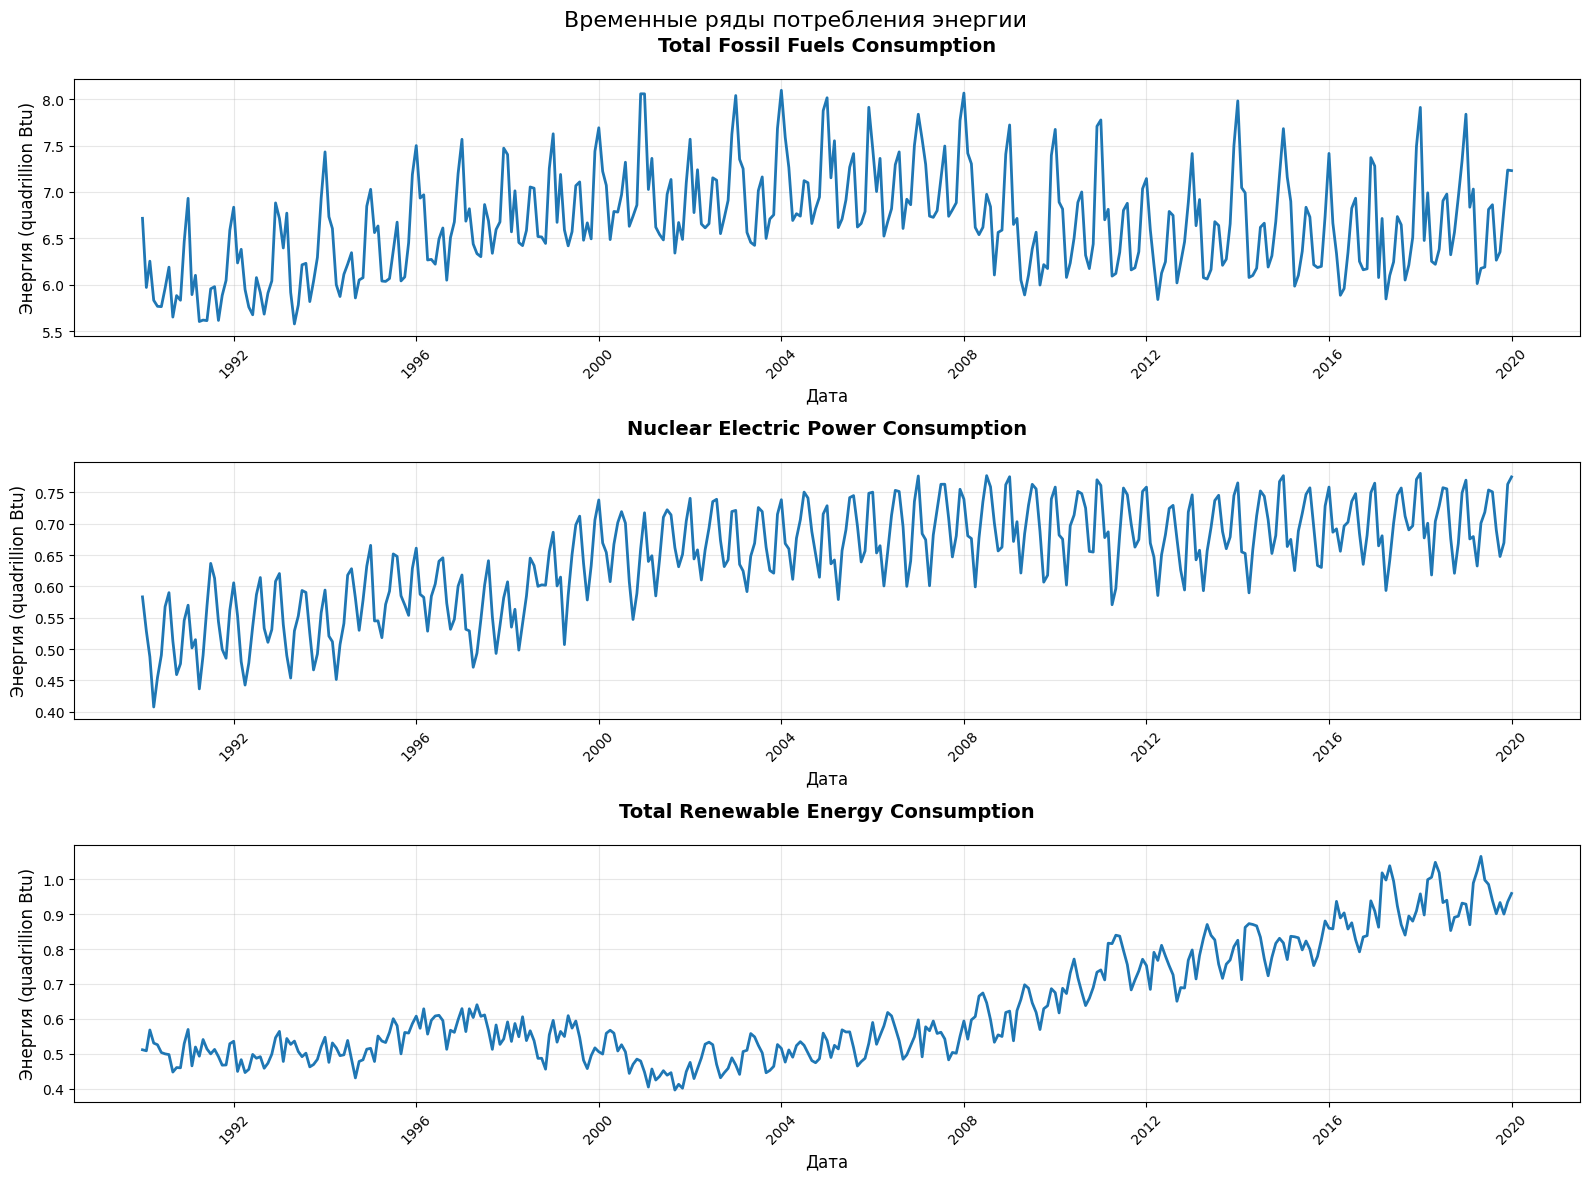

In [5]:
# срез данных с 1990 до 2020
df_cropped = df[df['Date'].between('1990-01', '2020-01')]

consumption_cols = [col for col in df_cropped.columns if 'Consumption' in col and 'Total Primary Energy' not in col]
cols = consumption_cols + ['Date']
df_cons = df_cropped[cols]
df_cons.set_index('Date', inplace=True)
df_cons.index = df_cons.index.to_timestamp()

fig, axes = plt.subplots(3, 1, figsize=(16, 12))
axes = axes.ravel()

for i, col in enumerate(consumption_cols):
    axes[i].plot(df_cons.index, df_cons[col], linewidth=2)
    axes[i].set_title(col, fontsize=14, fontweight='bold', pad=20)
    axes[i].set_xlabel('Дата', fontsize=12)
    axes[i].set_ylabel('Энергия (quadrillion Btu)', fontsize=12)
    axes[i].grid(True, alpha=0.3)
    axes[i].tick_params(axis='x', rotation=45)

plt.suptitle('Временные ряды потребления энергии', fontsize=16)
plt.tight_layout()
plt.show()

# Fossil Fuels

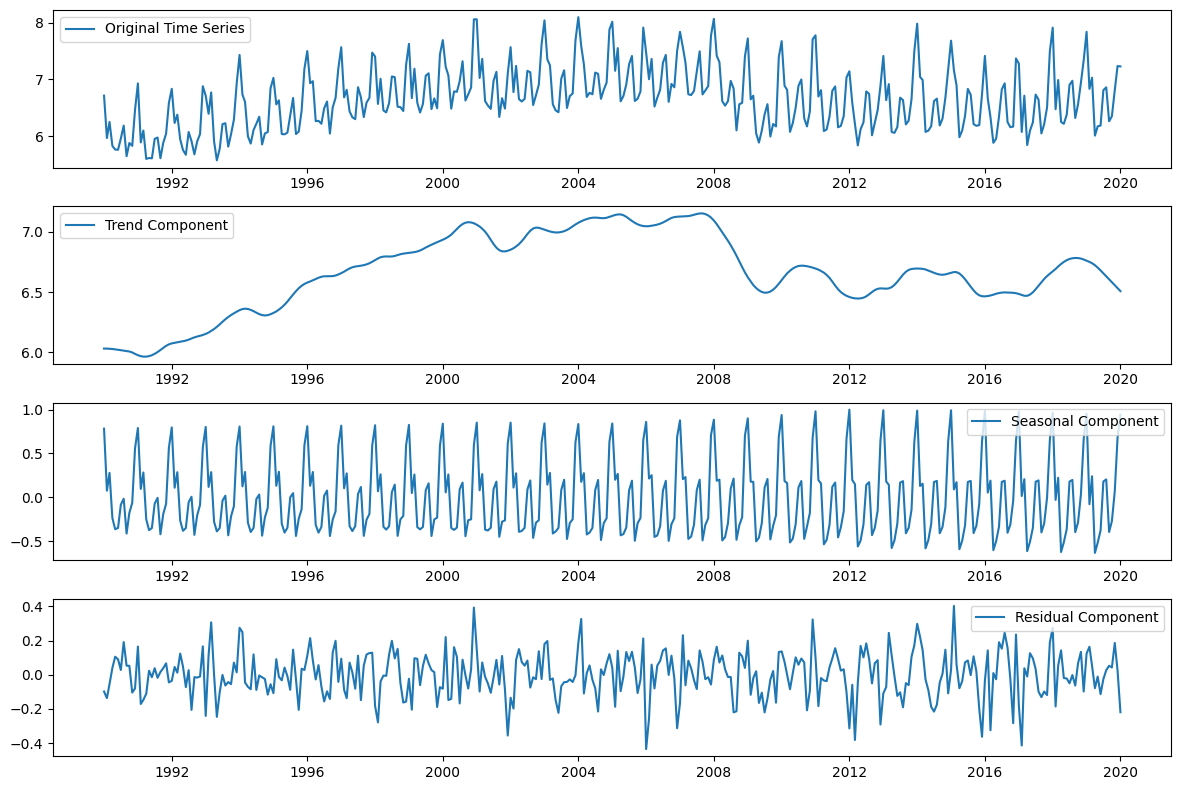

In [5]:
stl_fossil = STL(df_cons['Total Fossil Fuels Consumption'], seasonal=13)
result_fossil = stl_fossil.fit()
# Извлечение компонентов
trend = result_fossil.trend
seasonal = result_fossil.seasonal
residual = result_fossil.resid

# Построение графика декомпозиции
plt.figure(figsize=(12, 8))
plt.subplot(411)
plt.plot(df_cons['Total Fossil Fuels Consumption'], label='Original Time Series')
plt.legend(loc='upper left')
plt.subplot(412)
plt.plot(trend, label='Trend Component')
plt.legend(loc='upper left')
plt.subplot(413)
plt.plot(seasonal, label='Seasonal Component')
plt.legend(loc='upper right')
plt.subplot(414)
plt.plot(residual, label='Residual Component')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

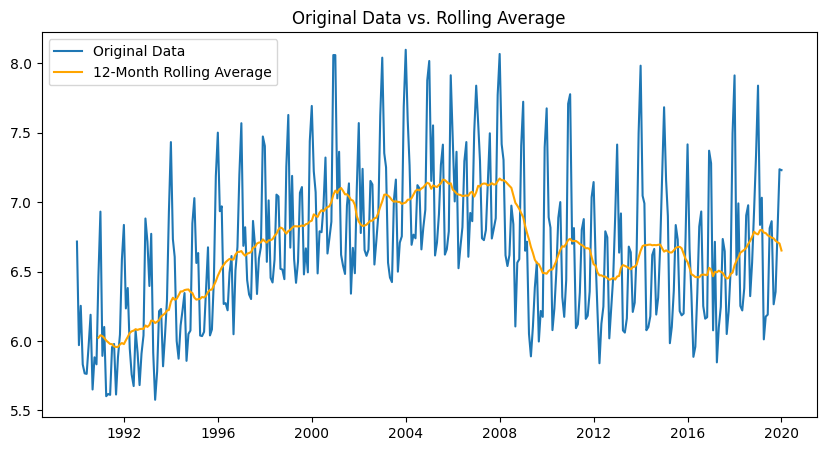

In [6]:
# Расчет скользящего среднего за 12 месяцев
df_cons['rolling_avg'] = df_cons['Total Fossil Fuels Consumption'].rolling(window=12).mean()

plt.figure(figsize=(10, 5))
plt.plot(df_cons['Total Fossil Fuels Consumption'], label='Original Data')
plt.plot(df_cons['rolling_avg'], label='12-Month Rolling Average', color='orange')
plt.title('Original Data vs. Rolling Average')
plt.legend()
plt.show()

# Nuclear ELectricity

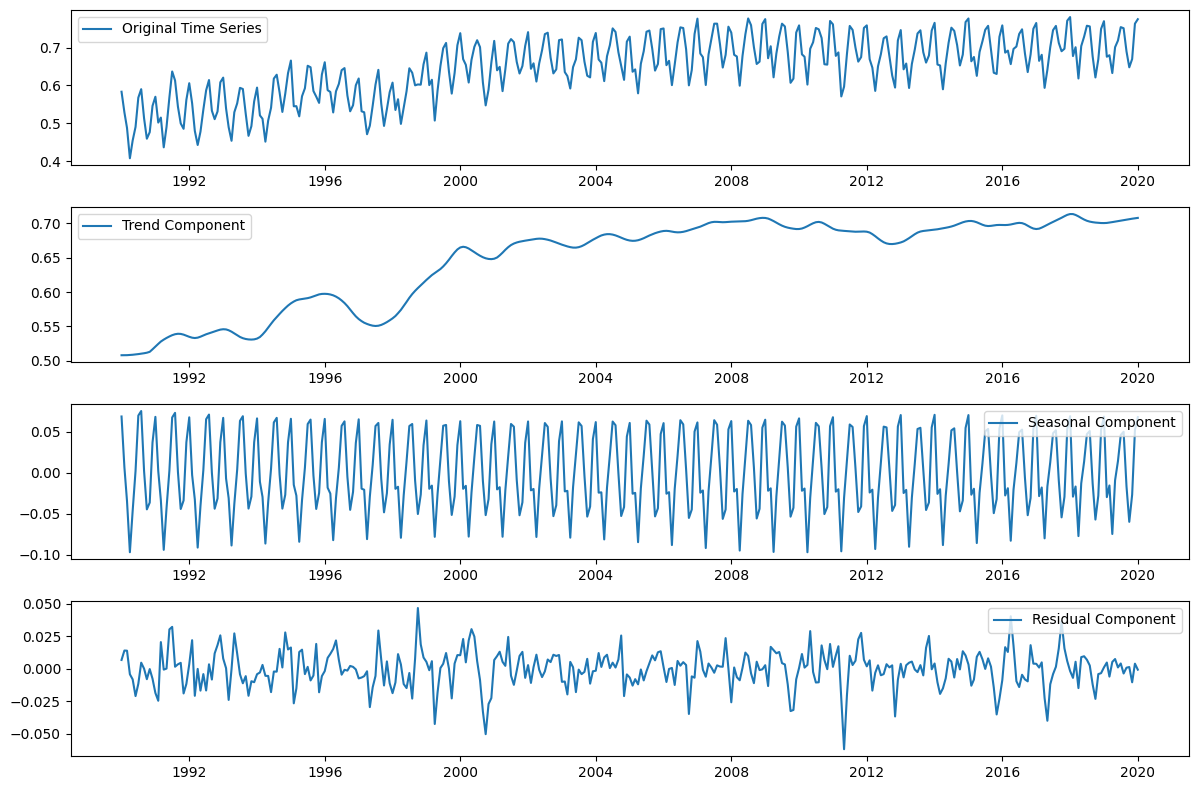

In [7]:
stl_nuclear = STL(df_cons['Nuclear Electric Power Consumption'], seasonal=13)
result_nuclear = stl_nuclear.fit()
# Извлечение компонентов
trend = result_nuclear.trend
seasonal = result_nuclear.seasonal
residual = result_nuclear.resid

# Построение графика декомпозиции
plt.figure(figsize=(12, 8))
plt.subplot(411)
plt.plot(df_cons['Nuclear Electric Power Consumption'], label='Original Time Series')
plt.legend(loc='upper left')
plt.subplot(412)
plt.plot(trend, label='Trend Component')
plt.legend(loc='upper left')
plt.subplot(413)
plt.plot(seasonal, label='Seasonal Component')
plt.legend(loc='upper right')
plt.subplot(414)
plt.plot(residual, label='Residual Component')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

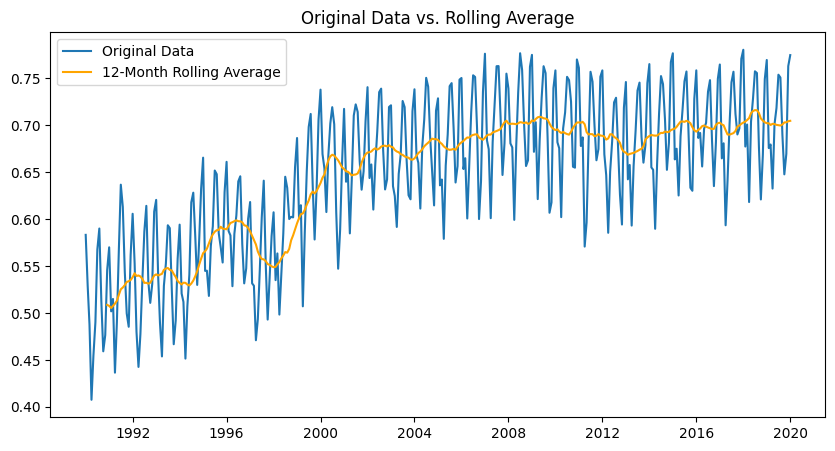

In [8]:
# Расчет скользящего среднего за 12 месяцев
df_cons['rolling_avg'] = df_cons['Nuclear Electric Power Consumption'].rolling(window=12).mean()

plt.figure(figsize=(10, 5))
plt.plot(df_cons['Nuclear Electric Power Consumption'], label='Original Data')
plt.plot(df_cons['rolling_avg'], label='12-Month Rolling Average', color='orange')
plt.title('Original Data vs. Rolling Average')
plt.legend()
plt.show()

# Renewable Energy

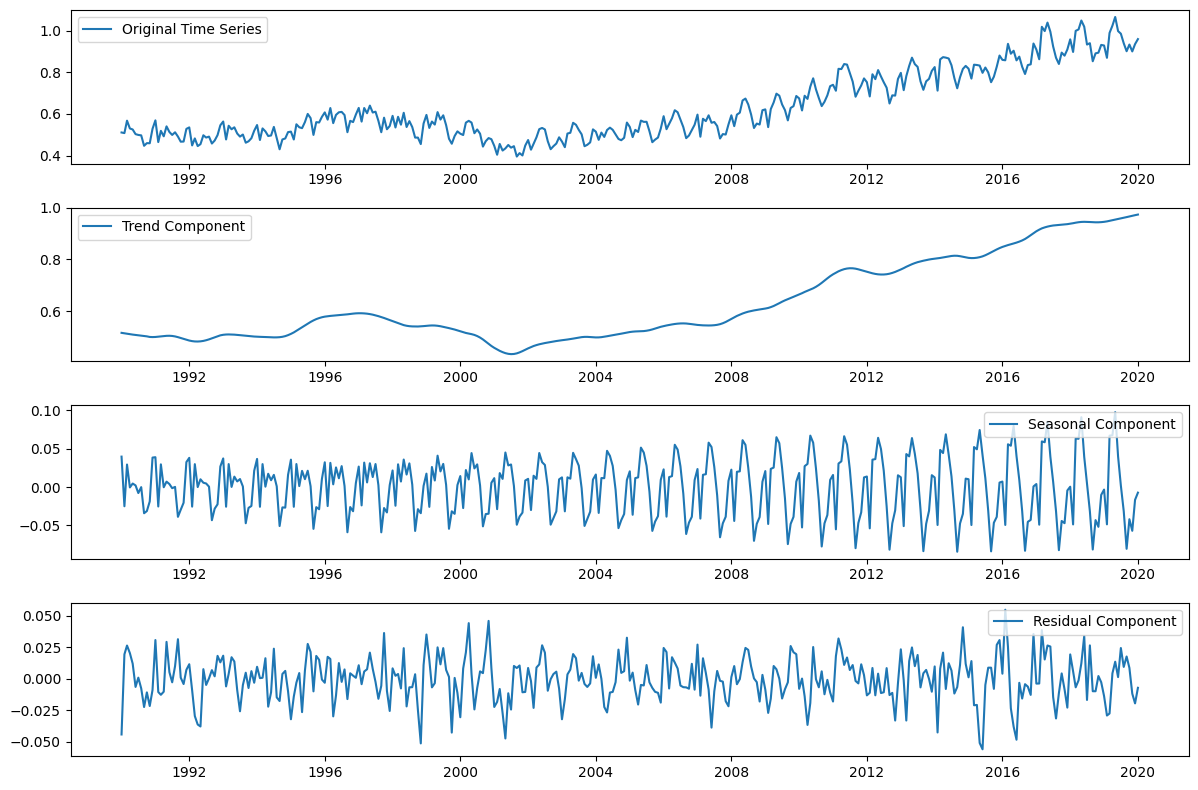

In [9]:
stl_renewable = STL(df_cons['Total Renewable Energy Consumption'], seasonal=13)
result_renewable = stl_renewable.fit()
# Извлечение компонентов
trend = result_renewable.trend
seasonal = result_renewable.seasonal
residual = result_renewable.resid

# Построение графика декомпозиции
plt.figure(figsize=(12, 8))
plt.subplot(411)
plt.plot(df_cons['Total Renewable Energy Consumption'], label='Original Time Series')
plt.legend(loc='upper left')
plt.subplot(412)
plt.plot(trend, label='Trend Component')
plt.legend(loc='upper left')
plt.subplot(413)
plt.plot(seasonal, label='Seasonal Component')
plt.legend(loc='upper right')
plt.subplot(414)
plt.plot(residual, label='Residual Component')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

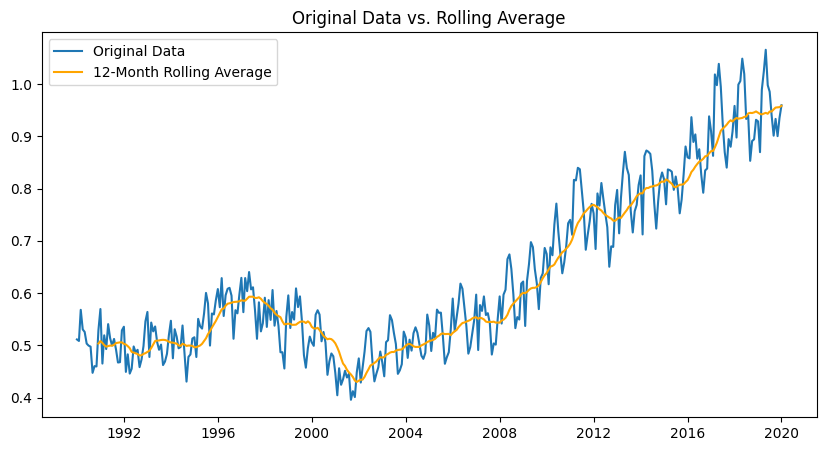

In [10]:
# Расчет скользящего среднего за 12 месяцев
df_cons['rolling_avg'] = df_cons['Total Renewable Energy Consumption'].rolling(window=12).mean()

plt.figure(figsize=(10, 5))
plt.plot(df_cons['Total Renewable Energy Consumption'], label='Original Data')
plt.plot(df_cons['rolling_avg'], label='12-Month Rolling Average', color='orange')
plt.title('Original Data vs. Rolling Average')
plt.legend()
plt.show()

# Тест Дики-Фуллера

In [7]:
def check_stationarity(timeseries):
    result = adfuller(timeseries, autolag='AIC')
    return result[1]

print("ADF для рядов")

DF_values = []
for column in consumption_cols:
    p_value = check_stationarity(df_cons[column])
    DF_values.append(p_value)
    print(f"Column '{column}': p‑value = {p_value}")

ADF для рядов
Column 'Total Fossil Fuels Consumption': p‑value = 0.135712151212935
Column 'Nuclear Electric Power Consumption': p‑value = 0.27817749297895356
Column 'Total Renewable Energy Consumption': p‑value = 0.9858095816996907


# Тест Квятковского — Филлипса — Шмидта — Шина

In [8]:
def check_kpss_stationarity(timeseries, regression='c'):
    result = kpss(timeseries.dropna(), regression=regression, nlags='auto')
    p_val = result[1]
    return p_val

print("KPSS для рядов")

KPSS_values = []
for column in consumption_cols:
    p_value = check_kpss_stationarity(df_cons[column])
    KPSS_values.append(p_value)
    print(f"Column '{column}': p‑value = {p_value}")

KPSS для рядов
Column 'Total Fossil Fuels Consumption': p‑value = 0.01
Column 'Nuclear Electric Power Consumption': p‑value = 0.01
Column 'Total Renewable Energy Consumption': p‑value = 0.01


Сводная таблица метрик

In [14]:
table_data = []
for i, column in enumerate(consumption_cols):
    table_data.append([column, f"{DF_values[i]:.5f}", f"{KPSS_values[i]:.5f}"])

print(tabulate(
    table_data,
    headers=["Column", "ADF p-value", "KPSS p-value"],
    tablefmt="grid",
    floatfmt=".5f"
))

+------------------------------------+---------------+----------------+
| Column                             |   ADF p-value |   KPSS p-value |
+====================================+===============+================+
| Total Fossil Fuels Consumption     |       0.13571 |        0.01000 |
+------------------------------------+---------------+----------------+
| Nuclear Electric Power Consumption |       0.27818 |        0.01000 |
+------------------------------------+---------------+----------------+
| Total Renewable Energy Consumption |       0.98581 |        0.01000 |
+------------------------------------+---------------+----------------+


# Детрендирование

Линейный detrend

In [45]:
df_detrend = pd.DataFrame(
    index=df_cons.index,
    columns=consumption_cols,
    data=detrend(df_cons[consumption_cols])
)

trend_df = df_cons - df_detrend

DF_values = []
for column in consumption_cols:
    p_value = check_stationarity(df_detrend[column])
    DF_values.append(p_value)

KPSS_values = []
for column in consumption_cols:
    p_value = check_kpss_stationarity(df_detrend[column])
    KPSS_values.append(p_value)

table_data = []
for i, column in enumerate(consumption_cols):
    table_data.append([column, f"{DF_values[i]:.5f}", f"{KPSS_values[i]:.5f}"])

print(tabulate(
    table_data,
    headers=["Column", "ADF p-value", "KPSS p-value"],
    tablefmt="grid",
    floatfmt=".5f"
))

+------------------------------------+---------------+----------------+
| Column                             |   ADF p-value |   KPSS p-value |
+====================================+===============+================+
| Total Fossil Fuels Consumption     |       0.04563 |        0.01000 |
+------------------------------------+---------------+----------------+
| Nuclear Electric Power Consumption |       0.04563 |        0.01000 |
+------------------------------------+---------------+----------------+
| Total Renewable Energy Consumption |       0.04563 |        0.01000 |
+------------------------------------+---------------+----------------+


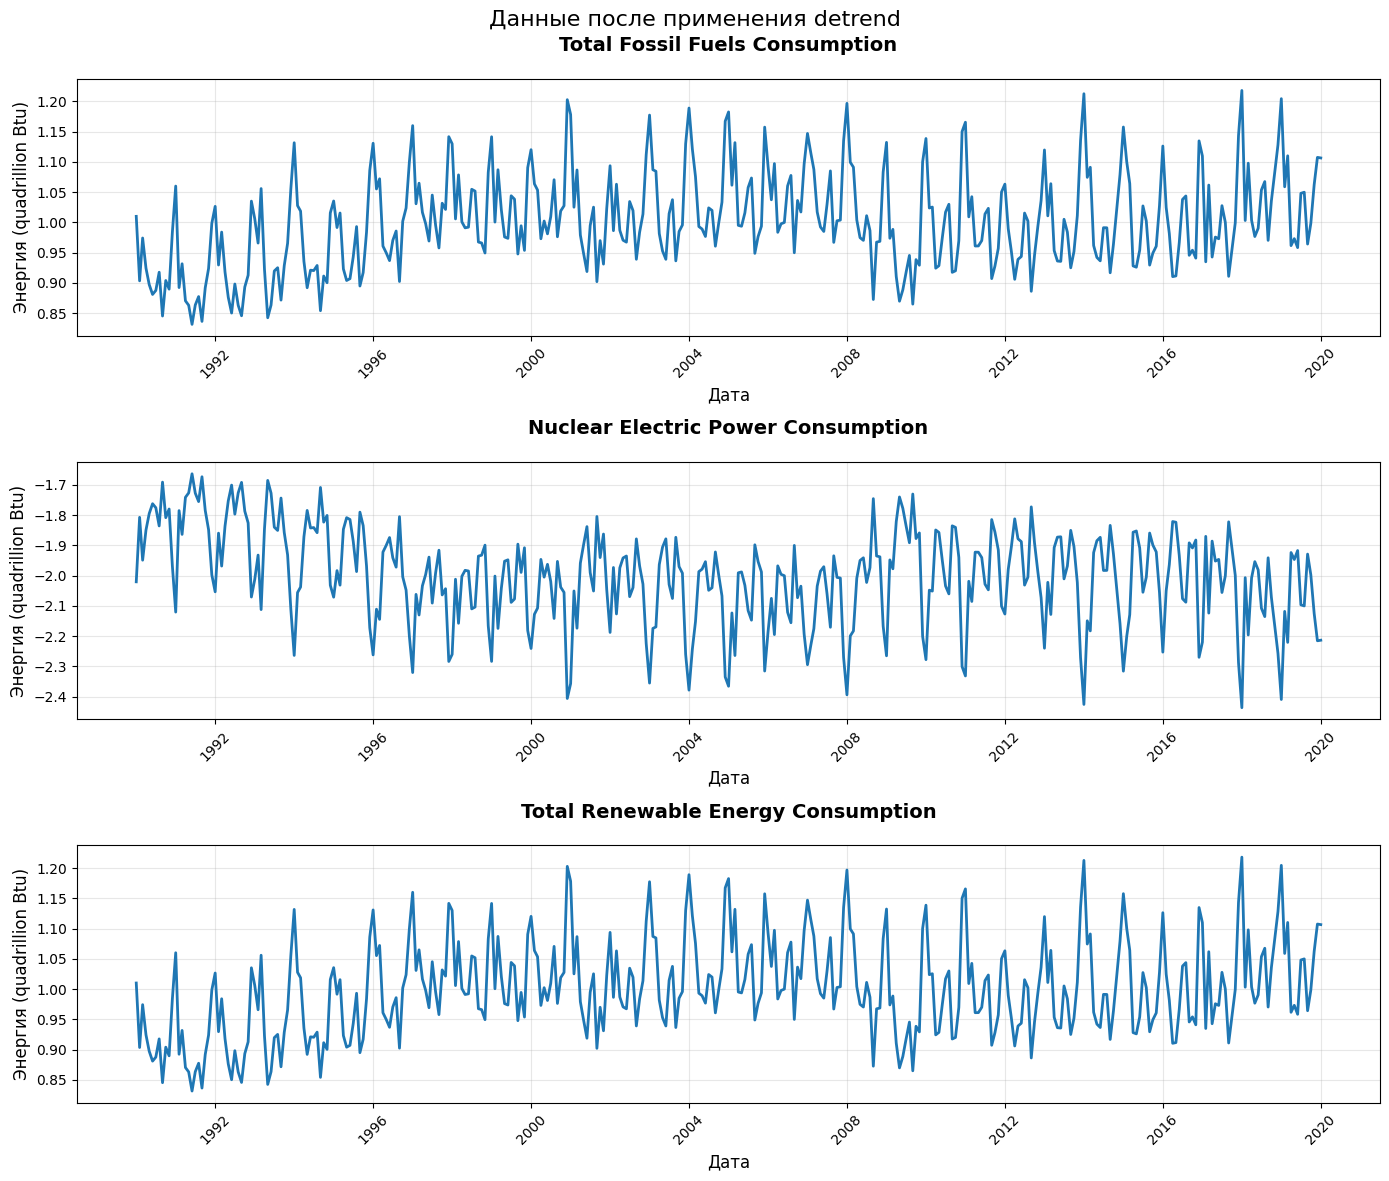

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
axes = axes.ravel()

for i, col in enumerate(consumption_cols):
    axes[i].plot(df_detrend.index, df_detrend[col], linewidth=2)
    axes[i].set_title(col, fontsize=14, fontweight='bold', pad=20)
    axes[i].set_xlabel('Дата', fontsize=12)
    axes[i].set_ylabel('Энергия (quadrillion Btu)', fontsize=12)
    axes[i].grid(True, alpha=0.3)
    axes[i].tick_params(axis='x', rotation=45)

plt.suptitle('Данные после применения detrend', fontsize=16)
plt.tight_layout()
plt.show()

Дифферинцирование

In [9]:
df_diff = df_detrend.diff().dropna()

DF_values = []
for column in consumption_cols:
    p_value = check_stationarity(df_diff[column])
    DF_values.append(p_value)

KPSS_values = []
for column in consumption_cols:
    p_value = check_kpss_stationarity(df_diff[column])
    KPSS_values.append(p_value)

table_data = []
for i, column in enumerate(consumption_cols):
    table_data.append([column, f"{DF_values[i]:.5f}", f"{KPSS_values[i]:.5f}"])

print(tabulate(
    table_data,
    headers=["Column", "ADF p-value", "KPSS p-value"],
    tablefmt="grid",
    floatfmt=".5f"
))

+------------------------------------+---------------+----------------+
| Column                             |   ADF p-value |   KPSS p-value |
+====================================+===============+================+
| Total Fossil Fuels Consumption     |       0.00000 |        0.10000 |
+------------------------------------+---------------+----------------+
| Nuclear Electric Power Consumption |       0.00000 |        0.10000 |
+------------------------------------+---------------+----------------+
| Total Renewable Energy Consumption |       0.00008 |        0.10000 |
+------------------------------------+---------------+----------------+


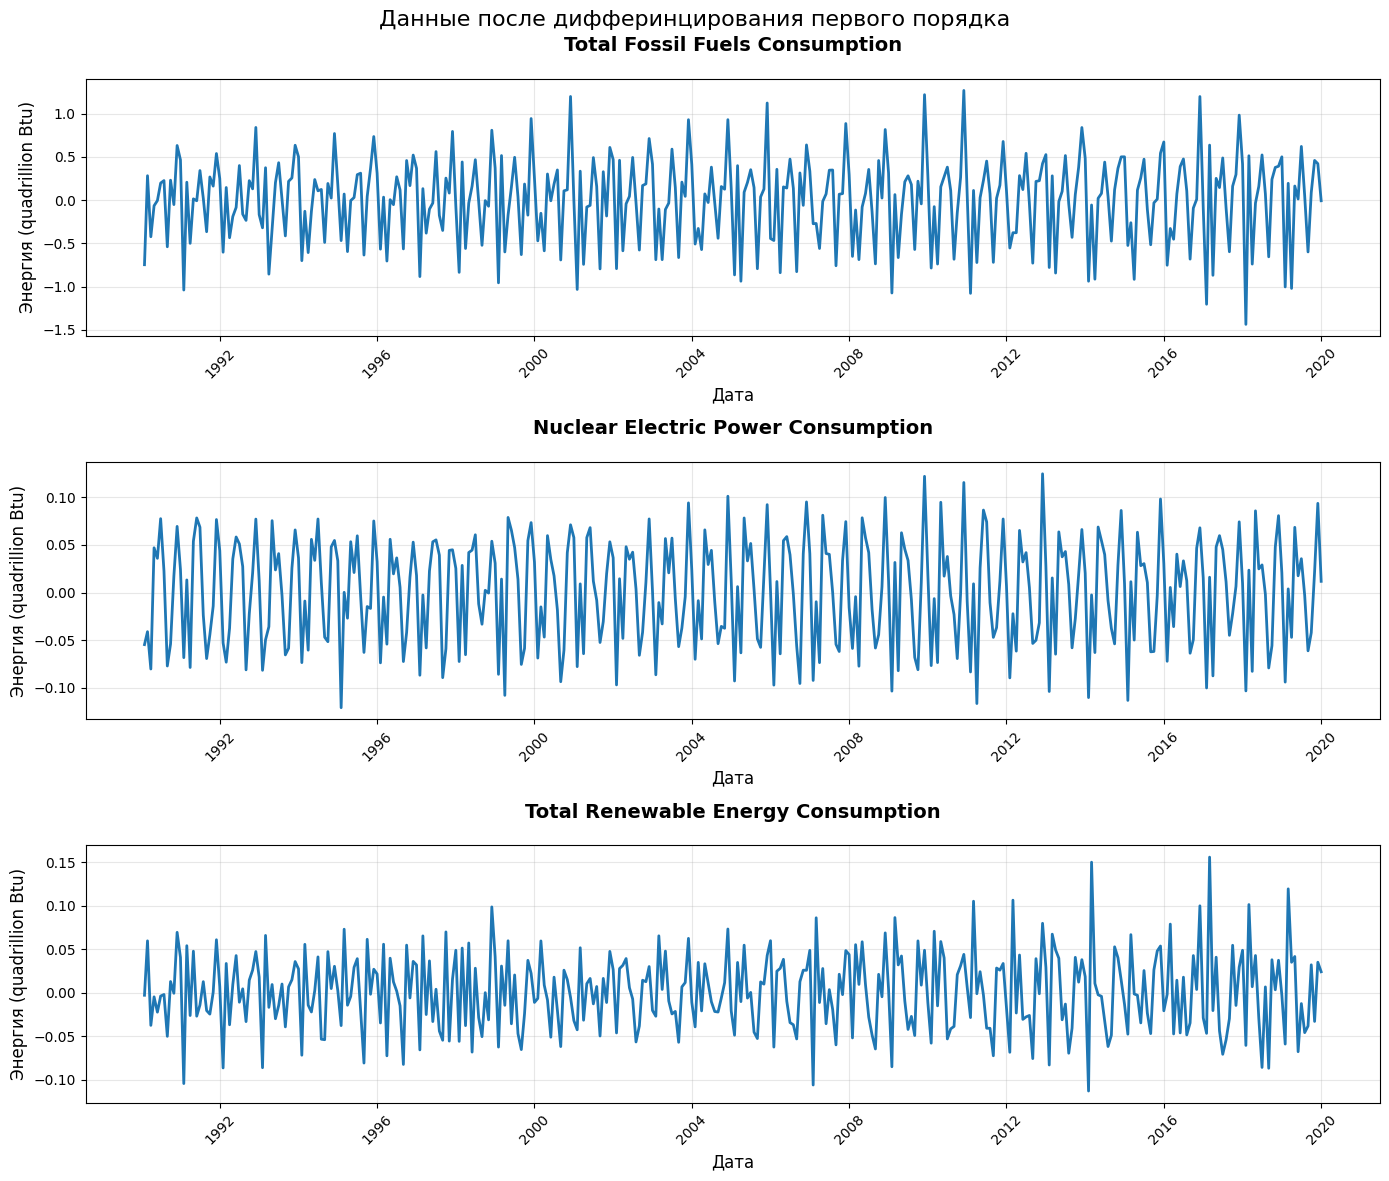

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
axes = axes.ravel()

for i, col in enumerate(consumption_cols):
    axes[i].plot(df_diff.index, df_diff[col], linewidth=2)
    axes[i].set_title(col, fontsize=14, fontweight='bold', pad=20)
    axes[i].set_xlabel('Дата', fontsize=12)
    axes[i].set_ylabel('Энергия (quadrillion Btu)', fontsize=12)
    axes[i].grid(True, alpha=0.3)
    axes[i].tick_params(axis='x', rotation=45)

plt.suptitle('Данные после дифферинцирования первого порядка', fontsize=16)
plt.tight_layout()
plt.show()

# Автокорреляции рядов

Fossil Fuel

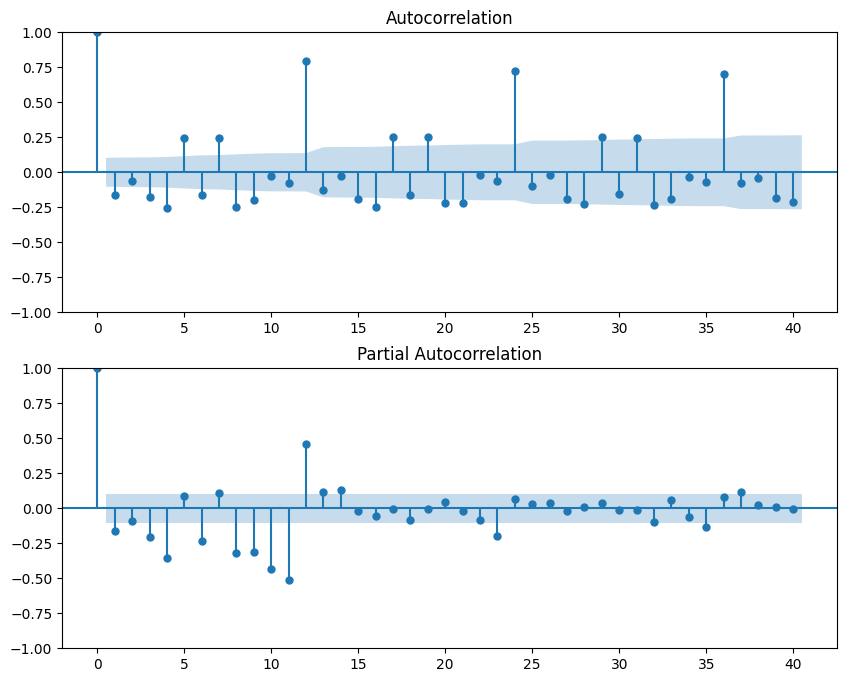

In [19]:
fig, ax = plt.subplots(2, 1, figsize=(10, 8))

plot_acf(df_diff['Total Fossil Fuels Consumption'], ax=ax[0], lags=40)
plot_pacf(df_diff['Total Fossil Fuels Consumption'], ax=ax[1], lags=40)

plt.show()

Nuclear Power

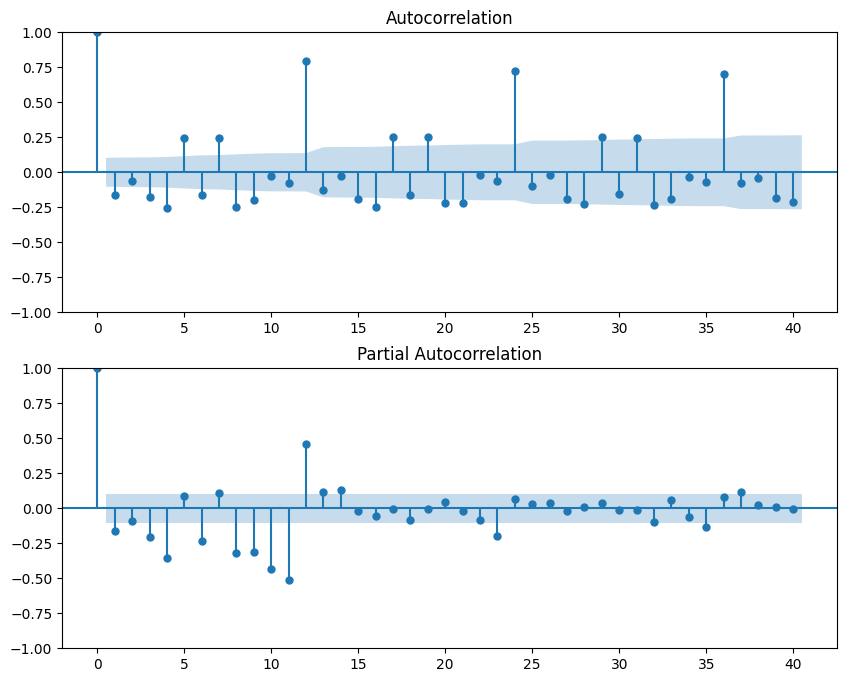

In [20]:
fig, ax = plt.subplots(2, 1, figsize=(10, 8))

plot_acf(df_diff['Nuclear Electric Power Consumption'], ax=ax[0], lags=40)
plot_pacf(df_diff['Nuclear Electric Power Consumption'], ax=ax[1], lags=40)

plt.show()

Renewable Energy

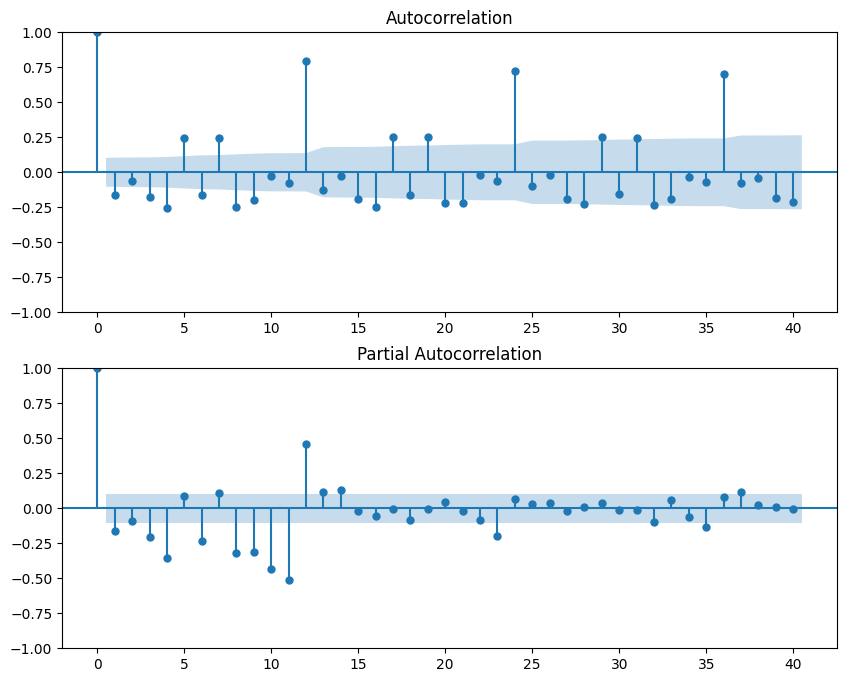

In [21]:
fig, ax = plt.subplots(2, 1, figsize=(10, 8))

plot_acf(df_diff['Total Renewable Energy Consumption'], ax=ax[0], lags=40)
plot_pacf(df_diff['Total Renewable Energy Consumption'], ax=ax[1], lags=40)

plt.show()

Метрики

In [22]:
def evaluate(y_true, y_pred, name="Model", column='Column'):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    print(f"{column}")
    print(f"{name}:")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print("-" * 30)

    return mae, rmse

# AR

In [49]:
split = int(len(df_diff) * 0.8)

train = df_diff.iloc[:split]
test = df_diff.iloc[split:]

ar_models = []
ar_forecasts = []

for col in consumption_cols:
    model = AutoReg(train[col], lags=12, old_names=False)
    fitted_model = model.fit()

    forecast = fitted_model.predict(start=test.index[0], end=test.index[-1])

    ar_models.append(fitted_model)
    ar_forecasts.append(forecast)
    evaluate(test[col], forecast, name="AR", column=col)

ar_levels = []

for i, col in enumerate(consumption_cols):

    forecast = ar_forecasts[i]

    last_detrended = df_detrend[col].iloc[split]
    forecast_detrended = forecast.cumsum() + last_detrended

    trend_part = trend_df[col].iloc[split+1:split+1+len(forecast_detrended)]

    forecast_levels = forecast_detrended + trend_part

    actual_levels = df_cons[col].iloc[split+1:split+1+len(forecast_levels)]

    ar_levels.append(forecast_levels)

Total Fossil Fuels Consumption
AR:
MAE: 0.0386
RMSE: 0.0515
------------------------------
Nuclear Electric Power Consumption
AR:
MAE: 0.0772
RMSE: 0.1030
------------------------------
Total Renewable Energy Consumption
AR:
MAE: 0.0386
RMSE: 0.0515
------------------------------


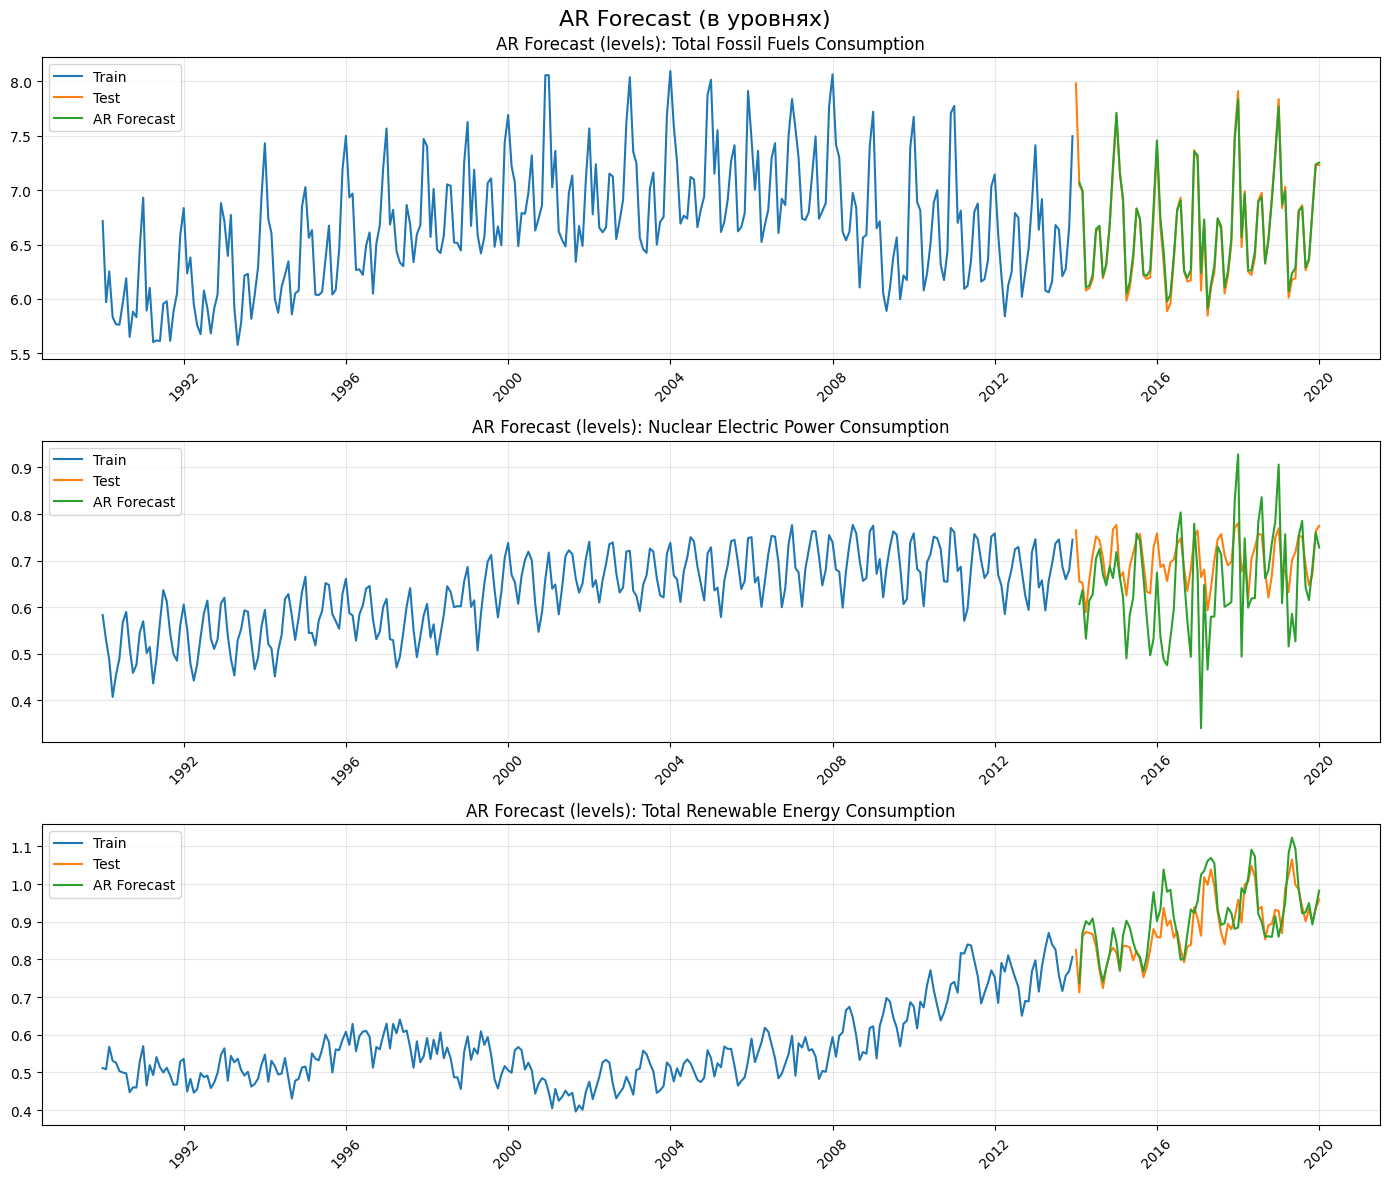

In [50]:
fig, axes = plt.subplots(len(consumption_cols), 1, figsize=(14, 12))
axes = axes.ravel()

for i, col in enumerate(consumption_cols):

    forecast_levels = ar_levels[i]

    axes[i].plot(df_cons.index[:split], df_cons[col].iloc[:split], label="Train")
    axes[i].plot(df_cons.index[split:], df_cons[col].iloc[split:], label="Test")

    axes[i].plot(forecast_levels.index, forecast_levels, label="AR Forecast")

    axes[i].set_title(f"AR Forecast (levels): {col}", fontsize=12)
    axes[i].grid(True, alpha=0.3)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend()

plt.suptitle("AR Forecast (в уровнях)", fontsize=16)
plt.tight_layout()
plt.show()

# SARIMAX
Исходные данные

In [24]:
sarima_models = []
sarima_forecasts = []

split = int(len(df_cons) * 0.8)

train = df_cons.iloc[:split]
test = df_cons.iloc[split:]

for col in consumption_cols:
    model = pm.auto_arima(
        train[col],
        seasonal=True,
        m=12,
        trace=False,
        error_action='ignore',
        suppress_warnings=True
    )

    forecast = model.predict(n_periods=len(test))

    forecast = forecast
    actual = test[col]

    sarima_models.append(model)
    sarima_forecasts.append(forecast)

    evaluate(actual, forecast, name="SARIMA (auto)", column=col)

Total Fossil Fuels Consumption
SARIMA (auto):
MAE: 0.1717
RMSE: 0.2249
------------------------------
Nuclear Electric Power Consumption
SARIMA (auto):
MAE: 0.0142
RMSE: 0.0183
------------------------------
Total Renewable Energy Consumption
SARIMA (auto):
MAE: 0.0288
RMSE: 0.0372
------------------------------


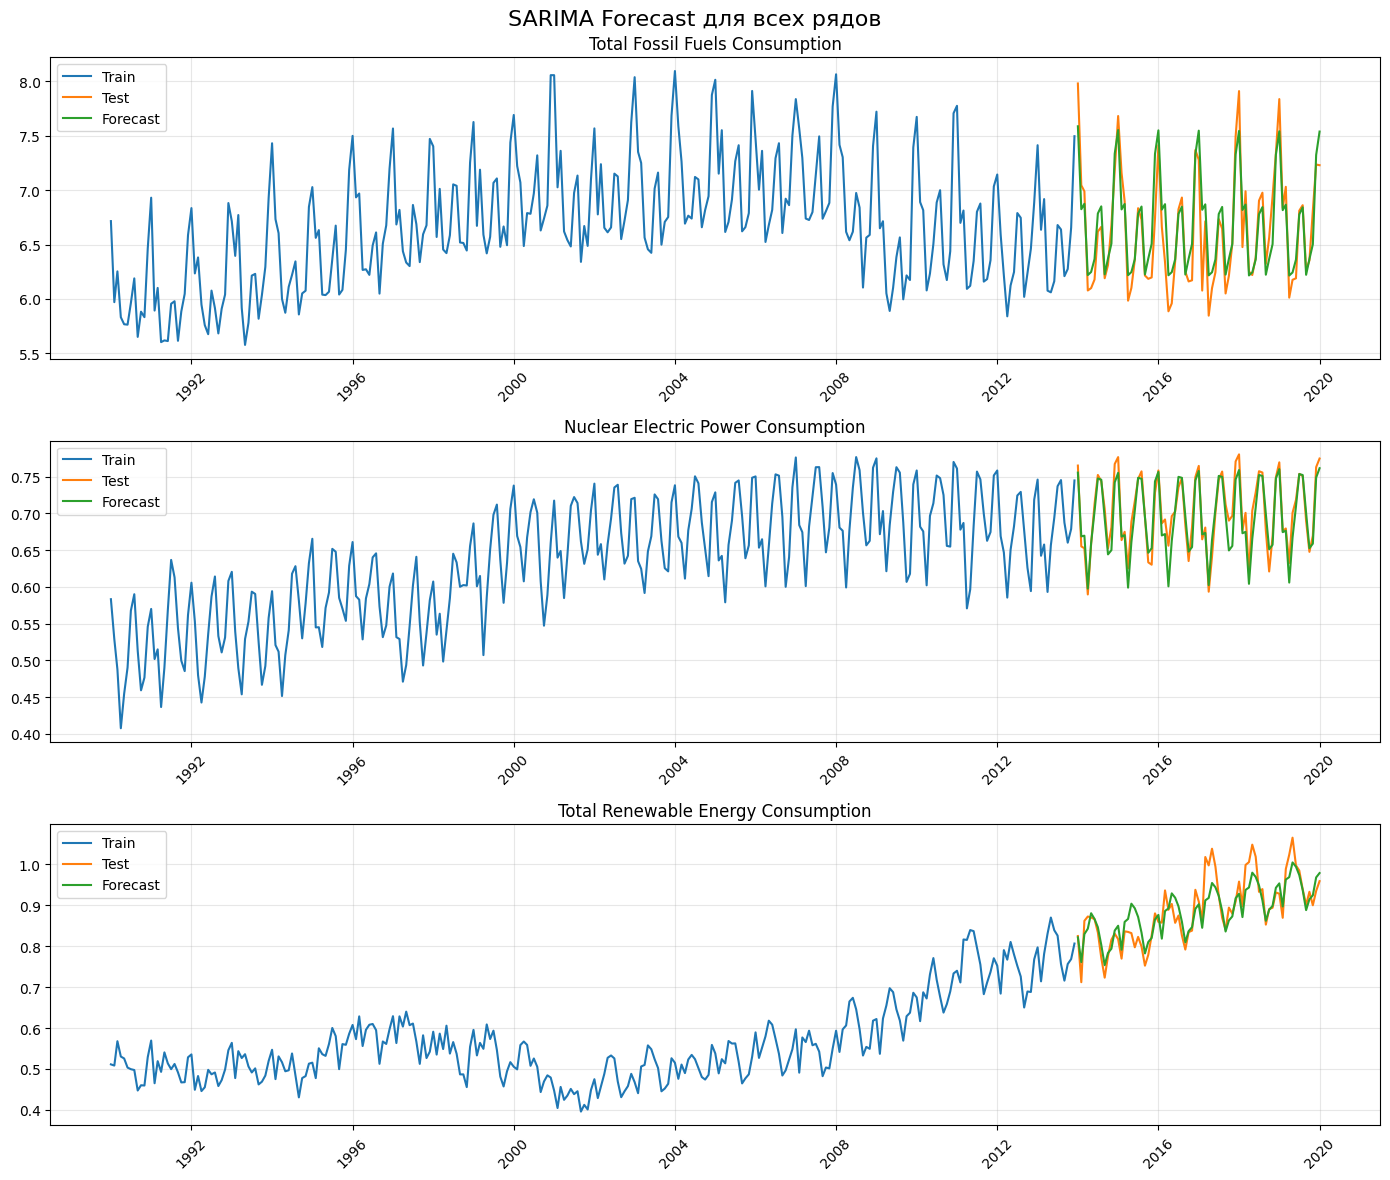

In [25]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
axes = axes.ravel()

for i, col in enumerate(consumption_cols):
    forecast = sarima_forecasts[i]

    axes[i].plot(train.index, train[col], label="Train")
    axes[i].plot(test.index, test[col], label="Test")
    axes[i].plot(test.index, forecast, label="Forecast")

    axes[i].set_title(col, fontsize=12)
    axes[i].grid(True, alpha=0.3)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend()

plt.suptitle("SARIMA Forecast для всех рядов", fontsize=16)
plt.tight_layout()
plt.show()

# XGBoost

In [40]:
df_ml = df_cons.copy()

# Лаги для всех consumption_cols
for col in consumption_cols:
    for lag in [1, 2, 3, 6, 12]:
        df_ml[f'{col}_lag{lag}'] = df_ml[col].shift(lag)

# Сезонность
df_ml['sin_month'] = np.sin(2 * np.pi * df_ml.index.month / 12)
df_ml['cos_month'] = np.cos(2 * np.pi * df_ml.index.month / 12)

X = df_ml.drop(columns=consumption_cols)
y = df_ml[consumption_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

gbdt_preds_log = []
models = []

for i, target in enumerate(consumption_cols):
    model = XGBRegressor(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        random_state=42,
        early_stopping_rounds=50,
    )

    model.fit(
        X_train, y_train.iloc[:, i],
        eval_set=[(X_test, y_test.iloc[:, i])],
        verbose=False
    )

    models.append(model)

    forecast = model.predict(X_test)
    gbdt_preds_log.append(forecast)
    actual = y_test.iloc[:, i]

    evaluate(actual, forecast, name="XGBoost", column=target)

Total Fossil Fuels Consumption
XGBoost:
MAE: 0.2003
RMSE: 0.2761
------------------------------
Nuclear Electric Power Consumption
XGBoost:
MAE: 0.0195
RMSE: 0.0232
------------------------------
Total Renewable Energy Consumption
XGBoost:
MAE: 0.1084
RMSE: 0.1268
------------------------------


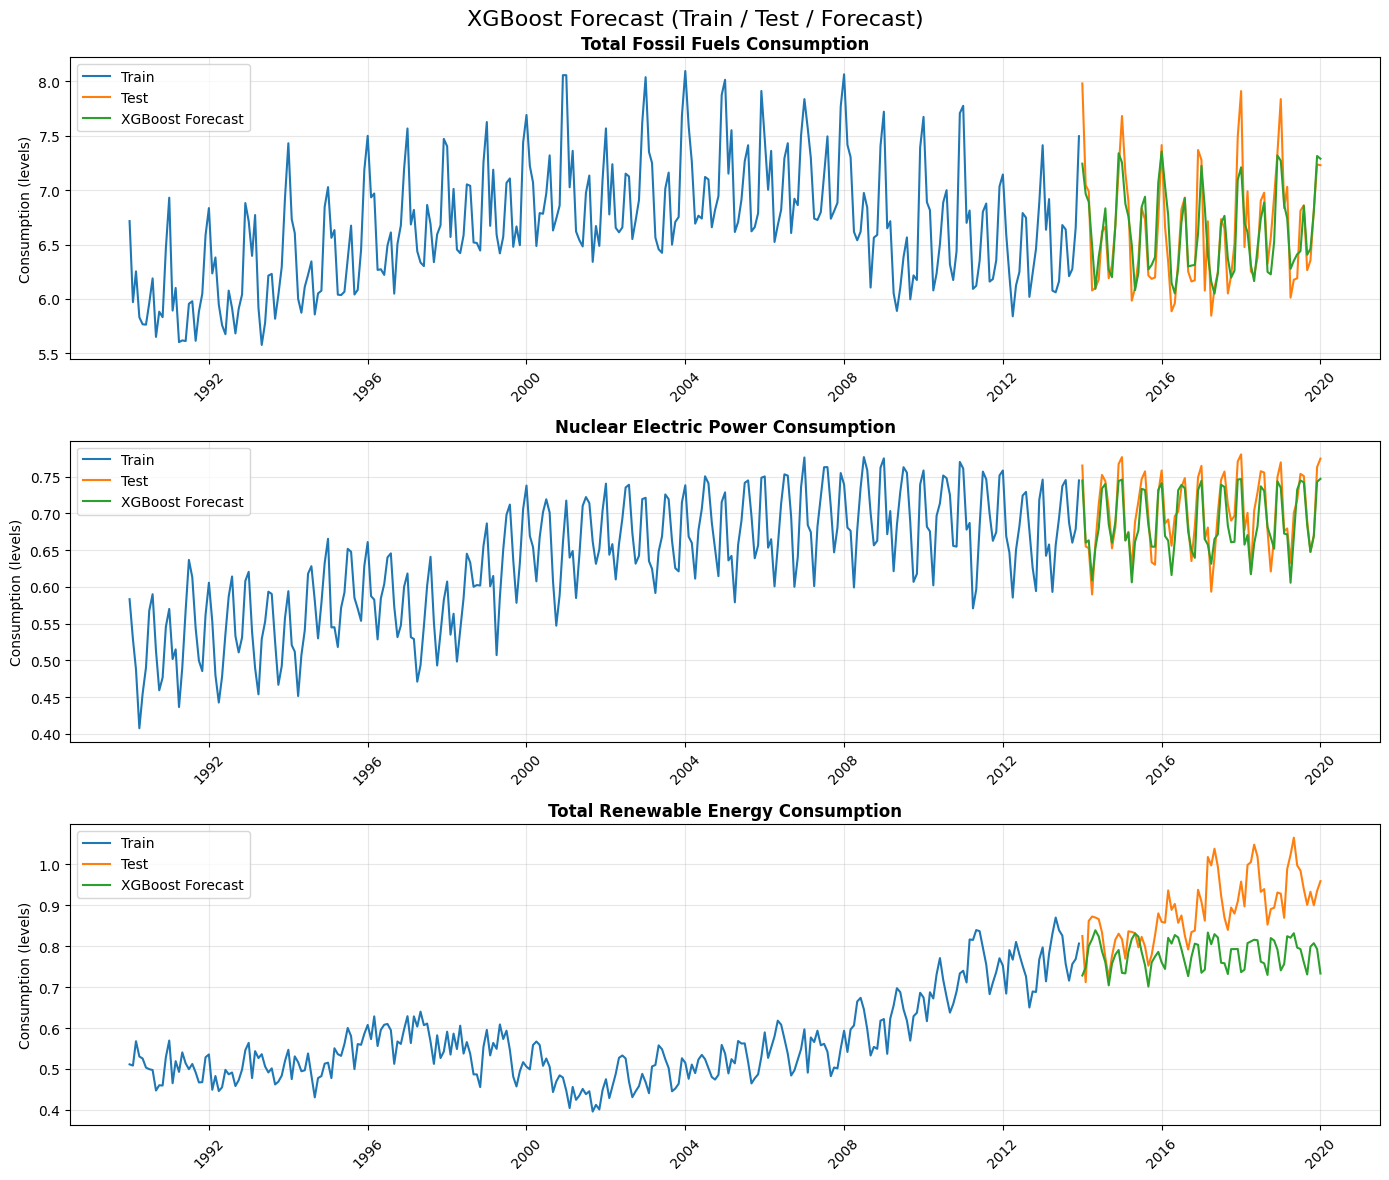

In [41]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
axes = axes.ravel()

for i, col in enumerate(consumption_cols):
    # прогноз
    pred = gbdt_preds_log[i]
    pred_series = pd.Series(pred, index=y_test.index)

    # train / test
    train_series = y_train.iloc[:, i]
    test_series = y_test.iloc[:, i]

    axes[i].plot(train_series.index, train_series, label="Train")
    axes[i].plot(test_series.index, test_series, label="Test")
    axes[i].plot(pred_series.index, pred_series, label="XGBoost Forecast")

    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].grid(True, alpha=0.3)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend()

    axes[i].set_ylabel('Consumption (levels)')

plt.suptitle("XGBoost Forecast (Train / Test / Forecast)", fontsize=16)
plt.tight_layout()
plt.show()

# Exponential Smoothng

In [42]:
# Списки для хранения моделей и прогнозов
hw_models = []
hw_forecasts = []

split = int(len(df_cons) * 0.8)
train = df_cons.iloc[:split]
test = df_cons.iloc[split:]

# Прогноз для каждого ряда
for col in consumption_cols:
    model = ExponentialSmoothing(
        train[col],
        trend="add",
        seasonal="add",
        seasonal_periods=12
    ).fit()

    # Прогноз на длину тестового периода
    forecast = model.forecast(len(test))

    # Сохраняем модель и прогноз
    hw_models.append(model)
    hw_forecasts.append(forecast)

    # Оценка прогноза
    evaluate(test[col], forecast, name="Holt-Winters", column=col)


Total Fossil Fuels Consumption
Holt-Winters:
MAE: 0.2907
RMSE: 0.3456
------------------------------
Nuclear Electric Power Consumption
Holt-Winters:
MAE: 0.0294
RMSE: 0.0342
------------------------------
Total Renewable Energy Consumption
Holt-Winters:
MAE: 0.0580
RMSE: 0.0703
------------------------------


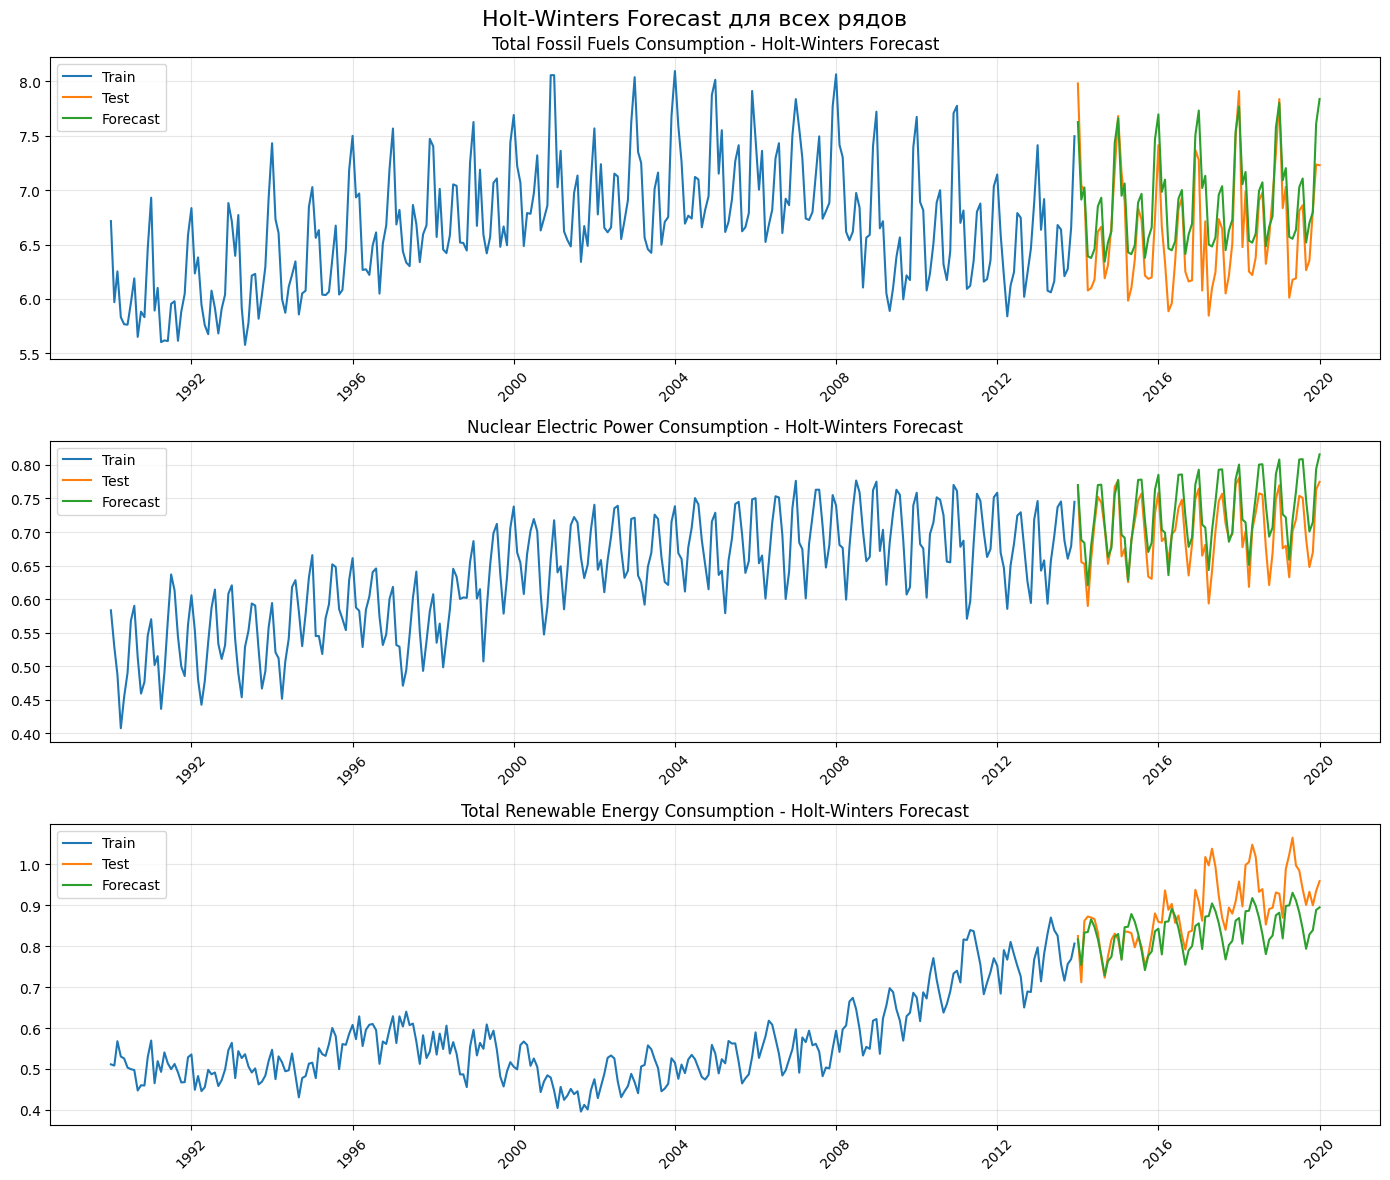

In [43]:
# Визуализация прогнозов
fig, axes = plt.subplots(len(consumption_cols), 1, figsize=(14, 12))
axes = axes.ravel()

for i, col in enumerate(consumption_cols):
    forecast = hw_forecasts[i]

    axes[i].plot(train.index, train[col], label="Train")
    axes[i].plot(test.index, test[col], label="Test")
    axes[i].plot(test.index, forecast, label="Forecast")

    axes[i].set_title(f"{col} - Holt-Winters Forecast", fontsize=12)
    axes[i].grid(True, alpha=0.3)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend()

plt.suptitle("Holt-Winters Forecast для всех рядов", fontsize=16)
plt.tight_layout()
plt.show()